# Lab 2 · Clean, connect and check

**In class:** Part A, guided, on a messy version of the penguins data · **At home:** Part B, the same steps on your own two tables
**Due:** Sunday, November 8 at 11:59 PM (extended for Election Day) · **Submit:** your repo URL on CourseWorks

Tonight's three skills:
1. **Clean** a messy CSV with pandas and load it into DuckDB
2. **Connect** two tables with a join, on a key you've checked
3. **Check** every join by counting rows before and after

Run cells top to bottom with **Shift+Enter**.

---
# Part A · Guided: messy penguins + a lookup table

## A1. Read the messy file with pandas

`penguins_raw.csv` is the same study as last week's penguins, in its original form: long column names, extra fields, comments. **pandas** is a Python library for working with tables; a table in pandas is called a **DataFrame**.

In [3]:
from pathlib import Path
import pandas as pd
import duckdb

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
raw = pd.read_csv(ROOT / "data" / "penguins_raw.csv")

print(raw.shape)   # (rows, columns)
raw.head()

(344, 17)


,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,2007-11-11,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,2007-11-11,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,2007-11-16,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,2007-11-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,2007-11-16,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN


How much is missing in each column? `isna()` marks missing values; `.sum()` counts them per column.

In [4]:
raw.isna().sum()

studyName                0
Sample Number            0
Species                  0
Region                   0
Island                   0
Stage                    0
Individual ID            0
Clutch Completion        0
Date Egg                 0
Culmen Length (mm)       2
Culmen Depth (mm)        2
Flipper Length (mm)      2
Body Mass (g)            2
Sex                     11
Delta 15 N (o/oo)       14
Delta 13 C (o/oo)       13
Comments               290
dtype: int64

Look at the species column. What would make it hard to use as a key?
空格，大小写

In [5]:
raw["Species"].value_counts()

Species
Adelie Penguin (Pygoscelis adeliae)          152
Gentoo penguin (Pygoscelis papua)            124
Chinstrap penguin (Pygoscelis antarctica)     68
Name: count, dtype: int64

**Notice:** long names with the Latin name in parentheses, and inconsistent capitals ("Adelie **P**enguin" vs. "Gentoo **p**enguin"). Text that *looks* the same to a person often won't match exactly in a join.

## A2. Three cleaning steps

**Step 1. Rename columns** to short, lowercase names with no spaces, so they're easy to type in SQL.

In [6]:
penguins = raw.rename(columns={
    "studyName": "study",
    "Individual ID": "individual_id",
    "Species": "species_raw",
    "Island": "island",
    "Date Egg": "date_egg",
    "Clutch Completion": "clutch_completion",
    "Culmen Length (mm)": "bill_length_mm",
    "Culmen Depth (mm)": "bill_depth_mm",
    "Flipper Length (mm)": "flipper_length_mm",
    "Body Mass (g)": "body_mass_g",
    "Sex": "sex",
})
penguins.columns.tolist()

['study',
 'Sample Number',
 'species_raw',
 'Region',
 'island',
 'Stage',
 'individual_id',
 'clutch_completion',
 'date_egg',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex',
 'Delta 15 N (o/oo)',
 'Delta 13 C (o/oo)',
 'Comments']

**Step 2. Standardize text.** Make `sex` lowercase, and pull the Latin name out of the parentheses into its own column. Scientific names are written the same way everywhere, which makes them a better key than the common name.

In [7]:
penguins["sex"] = penguins["sex"].str.lower()
penguins["latin_name"] = penguins["species_raw"].str.extract(r"\((.*)\)")   # text inside ( )

penguins[["species_raw", "latin_name", "sex"]].drop_duplicates().head(6)

,species_raw,latin_name,sex
0,Adelie Penguin (Pygoscelis adeliae),Pygoscelis adeliae,male
1,Adelie Penguin (Pygoscelis adeliae),Pygoscelis adeliae,female
3,Adelie Penguin (Pygoscelis adeliae),Pygoscelis adeliae,NaN
152,Gentoo penguin (Pygoscelis papua),Pygoscelis papua,female
153,Gentoo penguin (Pygoscelis papua),Pygoscelis papua,male
178,Gentoo penguin (Pygoscelis papua),Pygoscelis papua,NaN


**Step 3. Fix types and keep what you need.** The egg date came in as text; make it a real date. Then keep only the columns we'll use.

In [8]:
penguins["date_egg"] = pd.to_datetime(penguins["date_egg"])

penguins = penguins[[
    "study", "individual_id", "latin_name", "island", "date_egg", "clutch_completion",
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex",
]]
penguins.dtypes

study                           str
individual_id                   str
latin_name                      str
island                          str
date_egg             datetime64[us]
clutch_completion               str
bill_length_mm              float64
bill_depth_mm               float64
flipper_length_mm           float64
body_mass_g                 float64
sex                             str
dtype: object

## A3. Load it into DuckDB and verify with SQL

DuckDB can read a pandas DataFrame directly by its variable name. Always check the row count after moving data: **rows in should equal rows out.**

In [9]:
con = duckdb.connect(str(ROOT / "lab2.duckdb"))
con.sql("CREATE OR REPLACE TABLE penguins_clean AS SELECT * FROM penguins")

print("rows in pandas:", len(penguins))
con.sql("SELECT count(*) AS rows_in_duckdb FROM penguins_clean")

IOException: IO Error: Could not set lock on file "/workspaces/data-infra-project/lab2.duckdb": Conflicting lock is held in /usr/local/bin/python3.12 (PID 1850). See also https://duckdb.org/docs/stable/connect/concurrency

In [ ]:
con.sql("DESCRIBE penguins_clean")

┌───────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│    column_name    │ column_type │  null   │   key   │ default │  extra  │
│      varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ study             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ individual_id     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ latin_name        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ island            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ date_egg          │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ clutch_completion │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ bill_length_mm    │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ bill_depth_mm     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ flipper_length_mm │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ body_mass_

## A4. What is one row? Is the ID really an ID?

There's a column called `individual_id`. If it identified one penguin, every penguin would appear once per season. Let's check.

In [ ]:
con.sql("""
    SELECT count(*)                      AS rows,
           count(DISTINCT individual_id) AS distinct_ids
    FROM penguins_clean
""")

┌───────┬──────────────┐
│ rows  │ distinct_ids │
│ int64 │    int64     │
├───────┼──────────────┤
│   344 │          190 │
└───────┴──────────────┘

In [ ]:
con.sql("""
    SELECT study, latin_name, island, individual_id
    FROM penguins_clean
    WHERE individual_id = 'N11A1'
""")

┌─────────┬────────────────────┬─────────┬───────────────┐
│  study  │     latin_name     │ island  │ individual_id │
│ varchar │      varchar       │ varchar │    varchar    │
├─────────┼────────────────────┼─────────┼───────────────┤
│ PAL0708 │ Pygoscelis adeliae │ Biscoe  │ N11A1         │
│ PAL0809 │ Pygoscelis papua   │ Biscoe  │ N11A1         │
└─────────┴────────────────────┴─────────┴───────────────┘

**The same ID belongs to an Adélie penguin in one season and a Gentoo the next.** It can't be one bird. It's most likely a nest-and-adult label the researchers reused. So:

- `individual_id` **alone is not a key.** A column named "ID" isn't automatically unique; always check with `count(DISTINCT ...)`.
- **One row = one adult penguin at one nest in one breeding season.** That's the table's **grain**, and you should be able to say it for every table you use.

## A5. A lookup table to join

`species_lookup.csv` is a small reference table: one row per species, with its common name, Latin name, genus and group.

In [ ]:
con.sql(f"CREATE OR REPLACE TABLE species AS SELECT * FROM read_csv('{ROOT / 'data' / 'species_lookup.csv'}')")
con.sql("SELECT * FROM species")

┌───────────────────┬────────────────────────┬─────────────┬───────────────────────┐
│    common_name    │       latin_name       │    genus    │      group_name       │
│      varchar      │        varchar         │   varchar   │        varchar        │
├───────────────────┼────────────────────────┼─────────────┼───────────────────────┤
│ Adélie penguin    │ Pygoscelis adeliae     │ Pygoscelis  │ brush-tailed penguins │
│ Chinstrap penguin │ Pygoscelis antarcticus │ Pygoscelis  │ brush-tailed penguins │
│ Gentoo penguin    │ Pygoscelis papua       │ Pygoscelis  │ brush-tailed penguins │
│ Emperor penguin   │ Aptenodytes forsteri   │ Aptenodytes │ great penguins        │
└───────────────────┴────────────────────────┴─────────────┴───────────────────────┘

Before joining, check that the key is **unique** in the lookup table. If a key appeared twice, every matching penguin would be copied twice.

In [ ]:
con.sql("""
    SELECT latin_name, count(*) AS n
    FROM species
    GROUP BY latin_name
    HAVING count(*) > 1
""")   # no rows back = the key is unique

┌────────────┬───────┐
│ latin_name │   n   │
│  varchar   │ int64 │
└────────────┴───────┘
        0 rows      

## A6. Join, and count what comes out

`JOIN ... ON` lines up rows where the key matches. We expect **344** rows out, one per penguin row.

In [ ]:
con.sql("""
    SELECT count(*) AS rows_after_join
    FROM penguins_clean p
    JOIN species s ON p.latin_name = s.latin_name
""")

┌─────────────────┐
│ rows_after_join │
│      int64      │
├─────────────────┤
│             276 │
└─────────────────┘

**Only 276, not 344.** An inner `JOIN` silently drops rows that don't match. Nothing errored. This is a data cascade in the making.

## A7. Find what didn't match with a LEFT JOIN

A `LEFT JOIN` keeps every penguin row. Where there's no match, the lookup's columns come back empty (`NULL`), so we can find the problem rows.

In [ ]:
con.sql("""
    SELECT p.latin_name, count(*) AS unmatched_rows
    FROM penguins_clean p
    LEFT JOIN species s ON p.latin_name = s.latin_name
    WHERE s.latin_name IS NULL
    GROUP BY p.latin_name
""")

┌───────────────────────┬────────────────┐
│      latin_name       │ unmatched_rows │
│        varchar        │     int64      │
├───────────────────────┼────────────────┤
│ Pygoscelis antarctica │             68 │
└───────────────────────┴────────────────┘

Compare with the lookup: the data says **Pygoscelis antarctic*a***, the lookup says **Pygoscelis antarctic*us***. Two sources spelled the same species differently, and 68 penguins vanished from the join.

## A8. Fix the key, then join again

Fix it at the source of the problem (the cleaning step), then reload and rejoin.

In [ ]:
penguins["latin_name"] = penguins["latin_name"].replace(
    {"Pygoscelis antarctica": "Pygoscelis antarcticus"}
)
con.sql("CREATE OR REPLACE TABLE penguins_clean AS SELECT * FROM penguins")

con.sql("""
    SELECT count(*) AS rows_after_join
    FROM penguins_clean p
    JOIN species s ON p.latin_name = s.latin_name
""")   # now 344

┌─────────────────┐
│ rows_after_join │
│      int64      │
├─────────────────┤
│             344 │
└─────────────────┘

Which way you join matters. Start from the **lookup** with a `LEFT JOIN` to see species that have no penguins:

In [ ]:
con.sql("""
    SELECT s.common_name, count(p.latin_name) AS penguin_rows
    FROM species s
    LEFT JOIN penguins_clean p ON p.latin_name = s.latin_name
    GROUP BY s.common_name
    ORDER BY penguin_rows DESC
""")

┌───────────────────┬──────────────┐
│    common_name    │ penguin_rows │
│      varchar      │    int64     │
├───────────────────┼──────────────┤
│ Adélie penguin    │          152 │
│ Gentoo penguin    │          124 │
│ Chinstrap penguin │           68 │
│ Emperor penguin   │            0 │
└───────────────────┴──────────────┘

## A9. What a duplicate key does

Here we fake a lookup table that lists Gentoo twice, then join. Watch the row count.

In [ ]:
con.sql("""
    WITH species_with_dupe AS (
        SELECT * FROM species
        UNION ALL
        SELECT * FROM species WHERE common_name = 'Gentoo penguin'
    )
    SELECT count(*) AS rows_after_join
    FROM penguins_clean p
    JOIN species_with_dupe s ON p.latin_name = s.latin_name
""")   # 468: every Gentoo row was copied

┌─────────────────┐
│ rows_after_join │
│      int64      │
├─────────────────┤
│             468 │
└─────────────────┘

**344 became 468**, and every total or average involving Gentoos would now be wrong. That's why you check key uniqueness (A5) before every join.

## A10. Use the join to answer a question

Now that the tables connect, ask a question that needs both: the lookup's readable names, the penguin table's measurements.

In [ ]:
con.sql("""
    SELECT s.common_name,
           p.island,
           count(*)                    AS penguins,
           round(avg(p.body_mass_g))   AS avg_mass_g
    FROM penguins_clean p
    JOIN species s ON p.latin_name = s.latin_name
    GROUP BY s.common_name, p.island
    ORDER BY s.common_name, p.island
""")

┌───────────────────┬───────────┬──────────┬────────────┐
│    common_name    │  island   │ penguins │ avg_mass_g │
│      varchar      │  varchar  │  int64   │   double   │
├───────────────────┼───────────┼──────────┼────────────┤
│ Adélie penguin    │ Biscoe    │       44 │     3710.0 │
│ Adélie penguin    │ Dream     │       56 │     3688.0 │
│ Adélie penguin    │ Torgersen │       52 │     3706.0 │
│ Chinstrap penguin │ Dream     │       68 │     3733.0 │
│ Gentoo penguin    │ Biscoe    │      124 │     5076.0 │
└───────────────────┴───────────┴──────────┴────────────┘

### The join checklist (use it in Part B)

1. **Grain:** what is one row in each table?
2. **Key:** which column connects them, and is it **unique** in the lookup side?
3. **Clean the key** the same way on both sides (spelling, capitals, spaces, codes vs. names, types).
4. **Count rows** before and after. More rows = a duplicate key. Fewer = unmatched keys.
5. **LEFT JOIN … IS NULL** to see exactly what didn't match, then decide: fix, drop, or keep as unknown.

---
# Part B · At home: your own two tables

Apply the checklist to the two tables you chose in Lab 1. If you'd like to swap datasets, that's fine; you just need two public tables that share a column.

## B1. Load both tables with pandas

In [35]:
FILE_A = "restaurants_verified.csv"     # <- your main table's file in data/
FILE_B = "zillow_rent.csv"   # <- the related table's file in data/

a = pd.read_csv(
    ROOT / "data" / FILE_A,
    dtype={"clean_zip": "string"}
)
b = pd.read_csv(ROOT / "data" / FILE_B)
print("A:", a.shape, "  B:", b.shape)
a.head()

A: (62666, 12)   B: (8340, 150)


,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,lng,clean_zip
0,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703,35207
1,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",NaN,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,-86.773330,35217
2,3,6,Philly Fresh Cheesesteaks (541-B Graymont Ave),NaN,NaN,"American, Cheesesteak, Sandwiches, Alcohol",$,"541-B Graymont Ave, Birmingham, AL, 35204",35204,33.509800,-86.854640,35204
3,4,17,Papa Murphy's (1580 Montgomery Highway),NaN,NaN,Pizza,$,"1580 Montgomery Highway, Hoover, AL, 35226",35226,33.404439,-86.806614,35226
4,5,162,Nelson Brothers Cafe (17th St N),4.7,22.0,"Breakfast and Brunch, Burgers, Sandwiches",NaN,"314 17th St N, Birmingham, AL, 35203",35203,33.514730,-86.811700,35203


In [15]:
b.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,City,Metro,CountyName,2015-01-31,...,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30
0,91982,0,77494,zip,TX,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Fort Bend County,1523.248823,...,1861.337730,1844.950557,1832.377180,1809.796842,1803.579576,1806.842153,1822.980567,1842.282742,1848.264724,1861.280259
1,61148,1,8701,zip,NJ,NJ,Lakewood,"New York-Newark-Jersey City, NY-NJ-PA",Ocean County,NaN,...,NaN,2229.174364,2302.055536,2220.414957,2216.093120,2236.328814,2260.677273,2288.036086,2295.730999,2288.472222
2,91940,2,77449,zip,TX,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Harris County,1253.527809,...,1824.430462,1814.216704,1817.440029,1798.719287,1794.517496,1798.192679,1799.874522,1808.840939,1810.141289,1809.091495
3,92593,4,78660,zip,TX,TX,Pflugerville,"Austin-Round Rock-Georgetown, TX",Travis County,1163.665438,...,1591.690218,1589.589795,1586.879062,1588.873067,1590.712261,1587.225364,1599.244644,1603.500223,1607.345013,1599.980983
4,91926,5,77433,zip,TX,TX,Cypress,"Houston-The Woodlands-Sugar Land, TX",Harris County,1364.546238,...,1940.040023,1929.799967,1908.377529,1907.291239,1928.986718,1957.782642,1972.887808,1970.295091,1966.973581,1964.275264


**Grain** (double-click to edit). One row in table A is: ___. One row in table B is: ___.

## B2. Clean: at least three steps

Use the Part A steps as a model: rename columns, standardize text, fix types, drop columns you don't need. Write each step in its own line with a comment saying *why*.

In [37]:
# Step 1: rename columns (short, lowercase, no spaces)
# b = b.rename(columns={"RegionID": "ZIP_code",})

# Step 2: standardize the key text so both tables match
a["zip"] = a["clean_zip"].astype("string").str.strip()
b["zip"] = b["RegionName"].astype("string").str.strip()

# Step 3: fix a type, or drop rows/columns you don't need
# a["year"] = a["year"].astype(int)

a.head()
b.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,City,Metro,CountyName,2015-01-31,...,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30,zip
0,91982,0,77494,zip,TX,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Fort Bend County,1523.248823,...,1844.950557,1832.377180,1809.796842,1803.579576,1806.842153,1822.980567,1842.282742,1848.264724,1861.280259,77494
1,61148,1,8701,zip,NJ,NJ,Lakewood,"New York-Newark-Jersey City, NY-NJ-PA",Ocean County,NaN,...,2229.174364,2302.055536,2220.414957,2216.093120,2236.328814,2260.677273,2288.036086,2295.730999,2288.472222,8701
2,91940,2,77449,zip,TX,TX,Katy,"Houston-The Woodlands-Sugar Land, TX",Harris County,1253.527809,...,1814.216704,1817.440029,1798.719287,1794.517496,1798.192679,1799.874522,1808.840939,1810.141289,1809.091495,77449
3,92593,4,78660,zip,TX,TX,Pflugerville,"Austin-Round Rock-Georgetown, TX",Travis County,1163.665438,...,1589.589795,1586.879062,1588.873067,1590.712261,1587.225364,1599.244644,1603.500223,1607.345013,1599.980983,78660
4,91926,5,77433,zip,TX,TX,Cypress,"Houston-The Woodlands-Sugar Land, TX",Harris County,1364.546238,...,1929.799967,1908.377529,1907.291239,1928.986718,1957.782642,1972.887808,1970.295091,1966.973581,1964.275264,77433


## B3. Load into DuckDB and check the key

In [38]:
import duckdb

con = duckdb.connect()

In [39]:
con.sql("CREATE OR REPLACE TABLE table_a AS SELECT * FROM a")
con.sql("CREATE OR REPLACE TABLE table_b AS SELECT * FROM b")

KEY_A = "zip"   # <- after your renames
KEY_B = "zip"

# Is the key unique in table B? No rows back = unique.
con.sql(f"""
    SELECT "{KEY_B}", count(*) AS n
    FROM table_b
    GROUP BY "{KEY_B}"
    HAVING count(*) > 1
    LIMIT 10
""")

┌─────────┬───────┐
│   zip   │   n   │
│ varchar │ int64 │
└─────────┴───────┘
      0 rows     

## B4. Join and count

In [40]:
print("rows in table A:", con.sql("SELECT count(*) FROM table_a").fetchone()[0])

con.sql(f"""
    SELECT count(*) AS rows_after_join
    FROM table_a a
    JOIN table_b b ON a."{KEY_A}" = b."{KEY_B}"
""")

rows in table A: 62666


┌─────────────────┐
│ rows_after_join │
│      int64      │
├─────────────────┤
│           58682 │
└─────────────────┘

## B5. Find what didn't match

In [41]:
con.sql(f"""
    SELECT a."{KEY_A}", count(*) AS unmatched_rows
    FROM table_a a
    LEFT JOIN table_b b ON a."{KEY_A}" = b."{KEY_B}"
    WHERE b."{KEY_B}" IS NULL
    GROUP BY a."{KEY_A}"
    ORDER BY unmatched_rows DESC
    LIMIT 20
""")

┌─────────┬────────────────┐
│   zip   │ unmatched_rows │
│ varchar │     int64      │
├─────────┼────────────────┤
│ 76092   │            132 │
│ 22150   │            117 │
│ 97204   │             49 │
│ 25504   │             48 │
│ 78589   │             47 │
│ 00926   │             45 │
│ 25428   │             38 │
│ 54913   │             37 │
│ 26330   │             37 │
│ 53965   │             35 │
│ 00961   │             34 │
│ 98134   │             34 │
│ 53151   │             34 │
│ 75965   │             33 │
│ 26105   │             32 │
│ 35640   │             31 │
│ 00949   │             30 │
│ 05401   │             29 │
│ 25177   │             28 │
│ 05403   │             27 │
└─────────┴────────────────┘
  20 rows        2 columns

**What didn't match, and what will you do about it?** (fix the key, drop those rows, or keep them as unknown, and why)
**some 3 digit zip code appears?**


### debug process

In [42]:
print("Restaurant ZIP dtype:", a["clean_zip"].dtype)

print(
    a[a["zip"].astype("string").str.len() < 5]
    [["clean_zip", "zip"]].drop_duplicates().head(20)
)

Restaurant ZIP dtype: string
Empty DataFrame
Columns: [clean_zip, zip]
Index: []


In [28]:
files = [
    "restaurants.csv",
    "restaurants_clean.csv",
    "restaurants_verified.csv"
]

for file in files:
    df = pd.read_csv(ROOT / "data" / file, dtype=str)

    print(f"\n--- {file} ---")
    print("Rows:", len(df))
    print("ZIP columns:", [
        c for c in df.columns if "zip" in c.lower()
    ])


--- restaurants.csv ---
Rows: 63469
ZIP columns: ['zip_code']

--- restaurants_clean.csv ---
Rows: 62667
ZIP columns: ['zip_code', 'clean_zip']

--- restaurants_verified.csv ---
Rows: 62666
ZIP columns: ['zip_code', 'clean_zip']


In [31]:
files = [
    "restaurants.csv",
    "restaurants_clean.csv",
    "restaurants_verified.csv"
]

for file in files:
    df = pd.read_csv(ROOT / "data" / file, dtype=str)
    print(file)
    print(df.columns.tolist())
    print()

restaurants.csv
['id', 'position', 'name', 'score', 'ratings', 'category', 'price_range', 'full_address', 'zip_code', 'lat', 'lng']

restaurants_clean.csv
['id', 'position', 'name', 'score', 'ratings', 'category', 'price_range', 'full_address', 'zip_code', 'lat', 'lng', 'clean_zip']

restaurants_verified.csv
['id', 'position', 'name', 'score', 'ratings', 'category', 'price_range', 'full_address', 'zip_code', 'lat', 'lng', 'clean_zip']



In [33]:
tracking = (
    raw[["id", "zip_code"]]
    .rename(columns={"zip_code": "raw_zip"})
    .merge(
        clean[["id", "zip_code", "clean_zip"]].rename(
            columns={
                "zip_code": "clean_original_zip",
                "clean_zip": "clean_zip_stage"
            }
        ),
        on="id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        verified[["id", "clean_zip"]].rename(
            columns={"clean_zip": "verified_zip"}
        ),
        on="id",
        how="left",
        validate="one_to_one"
    )
)

tracking.head()

,id,raw_zip,clean_original_zip,clean_zip_stage,verified_zip
0,1,35207,35207,35207,35207
1,2,35217,35217,35217,35217
2,3,35204,35204,35204,35204
3,4,35226,35226,35226,35226
4,5,35203,35203,35203,35203


In [34]:
tracking[
    tracking["verified_zip"]
    .str.len()
    .lt(5)
    .fillna(False)
][
    ["id", "raw_zip", "clean_zip_stage", "verified_zip"]
].head(30)

,id,raw_zip,clean_zip_stage,verified_zip


### 证明之前没有问题

## B6. Answer one question that needs both tables

Write a query that joins the tables and uses columns from **both**, e.g. average GDP by region, complaints per 1,000 residents by ZIP code.

In [43]:
con.sql("""
    SELECT *
    FROM table_a a
    JOIN table_b b
    ON a.zip = b.zip
    LIMIT 10
""").df()

,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,...,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30,zip_1
0,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",NaN,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,...,969.874122,1028.864919,1039.244757,1036.880566,1009.049843,1016.026562,1008.442887,1035.034821,1023.944444,35217
1,4,17,Papa Murphy's (1580 Montgomery Highway),NaN,NaN,Pizza,$,"1580 Montgomery Highway, Hoover, AL, 35226",35226,33.404439,...,1574.876219,1578.862378,1609.430180,1608.498790,1624.333661,1648.910980,1673.215067,1695.709780,1719.066218,35226
2,5,162,Nelson Brothers Cafe (17th St N),4.7,22.0,"Breakfast and Brunch, Burgers, Sandwiches",NaN,"314 17th St N, Birmingham, AL, 35203",35203,33.514730,...,1406.533185,1403.405330,1410.699129,1388.361387,1402.742225,1414.277267,1418.106620,1399.153096,1384.299206,35203
3,6,75,Ocean Restaurant,NaN,NaN,"Seafood, Sushi, Steak",$$,"1218 20th Street South, Birmingham, AL, 35205",35205,33.498630,...,1030.183969,1031.227513,1038.133746,1044.871038,1043.610665,1041.099048,1043.030013,1051.953862,1066.927348,35205
4,7,27,Jinsei Sushi,4.7,63.0,"Sushi, Asian, Japanese",$,"1830 29th Ave S, Birmingham, AL, 35209",35209,33.480440,...,1376.624066,1373.634321,1381.362135,1379.215729,1370.976965,1371.261449,1372.252328,1372.052654,1385.297980,35209
5,8,26,Little India,NaN,NaN,"Vegetarian, Asian, Asian Fusion, Chinese, Indi...",$,"2236 Highland Ave, Birmingham, AL, 35205",35205,33.502259,...,1030.183969,1031.227513,1038.133746,1044.871038,1043.610665,1041.099048,1043.030013,1051.953862,1066.927348,35205
6,9,136,Captain D's (1284 Decatur Hwy),NaN,NaN,"Seafood, Fast Food, Fish and Chips, American",$,"1284 Decatur Hwy, Gardendale, AL, 35071",35071,33.657100,...,NaN,NaN,NaN,NaN,NaN,1938.672275,1921.337545,1944.779174,1941.666667,35071
7,10,51,Cajun Bistro Express,NaN,NaN,"Desserts, Vegetarian, Coffee and Tea",$,"1515 Pearson Ave SW, Birmingham, AL, 35211",35211,33.486840,...,1378.861084,1373.199634,1370.082971,1358.472056,1299.773096,1289.347405,1303.649102,1344.038754,1339.775641,35211
8,12,194,The Ice Cream Shop,NaN,NaN,"Ice Cream &amp; Frozen Yogurt, Comfort Food, D...",$,"4414 4th Ave 5, Birmingham, AL, 35222",35222,33.526420,...,1308.990307,1283.525923,1270.645084,1271.945480,1296.480396,1299.934782,1309.323565,1326.304915,1353.916667,35222
9,13,116,Bunrise Burgers,NaN,NaN,"Burgers, Fast Food, American, Comfort Food, Di...",NaN,"1100 Forestdale Boulevard, Birmingham, AL, 35214",35214,33.557410,...,1203.365137,1218.650984,1216.567185,1222.327122,1229.350931,1240.306308,1238.162192,1248.547603,1228.611111,35214


In [44]:
con.sql("""
    CREATE OR REPLACE TABLE joined_data AS
    SELECT *
    FROM table_a a
    JOIN table_b b
    ON a.zip = b.zip
""")

In [45]:
con.sql("SELECT * FROM joined_data LIMIT 10").df()

,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,...,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30,zip_1
0,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",NaN,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,...,969.874122,1028.864919,1039.244757,1036.880566,1009.049843,1016.026562,1008.442887,1035.034821,1023.944444,35217
1,4,17,Papa Murphy's (1580 Montgomery Highway),NaN,NaN,Pizza,$,"1580 Montgomery Highway, Hoover, AL, 35226",35226,33.404439,...,1574.876219,1578.862378,1609.430180,1608.498790,1624.333661,1648.910980,1673.215067,1695.709780,1719.066218,35226
2,5,162,Nelson Brothers Cafe (17th St N),4.7,22.0,"Breakfast and Brunch, Burgers, Sandwiches",NaN,"314 17th St N, Birmingham, AL, 35203",35203,33.514730,...,1406.533185,1403.405330,1410.699129,1388.361387,1402.742225,1414.277267,1418.106620,1399.153096,1384.299206,35203
3,6,75,Ocean Restaurant,NaN,NaN,"Seafood, Sushi, Steak",$$,"1218 20th Street South, Birmingham, AL, 35205",35205,33.498630,...,1030.183969,1031.227513,1038.133746,1044.871038,1043.610665,1041.099048,1043.030013,1051.953862,1066.927348,35205
4,7,27,Jinsei Sushi,4.7,63.0,"Sushi, Asian, Japanese",$,"1830 29th Ave S, Birmingham, AL, 35209",35209,33.480440,...,1376.624066,1373.634321,1381.362135,1379.215729,1370.976965,1371.261449,1372.252328,1372.052654,1385.297980,35209
5,8,26,Little India,NaN,NaN,"Vegetarian, Asian, Asian Fusion, Chinese, Indi...",$,"2236 Highland Ave, Birmingham, AL, 35205",35205,33.502259,...,1030.183969,1031.227513,1038.133746,1044.871038,1043.610665,1041.099048,1043.030013,1051.953862,1066.927348,35205
6,9,136,Captain D's (1284 Decatur Hwy),NaN,NaN,"Seafood, Fast Food, Fish and Chips, American",$,"1284 Decatur Hwy, Gardendale, AL, 35071",35071,33.657100,...,NaN,NaN,NaN,NaN,NaN,1938.672275,1921.337545,1944.779174,1941.666667,35071
7,10,51,Cajun Bistro Express,NaN,NaN,"Desserts, Vegetarian, Coffee and Tea",$,"1515 Pearson Ave SW, Birmingham, AL, 35211",35211,33.486840,...,1378.861084,1373.199634,1370.082971,1358.472056,1299.773096,1289.347405,1303.649102,1344.038754,1339.775641,35211
8,12,194,The Ice Cream Shop,NaN,NaN,"Ice Cream &amp; Frozen Yogurt, Comfort Food, D...",$,"4414 4th Ave 5, Birmingham, AL, 35222",35222,33.526420,...,1308.990307,1283.525923,1270.645084,1271.945480,1296.480396,1299.934782,1309.323565,1326.304915,1353.916667,35222
9,13,116,Bunrise Burgers,NaN,NaN,"Burgers, Fast Food, American, Comfort Food, Di...",NaN,"1100 Forestdale Boulevard, Birmingham, AL, 35214",35214,33.557410,...,1203.365137,1218.650984,1216.567185,1222.327122,1229.350931,1240.306308,1238.162192,1248.547603,1228.611111,35214


In [46]:
con.sql("""
    COPY joined_data
    TO 'restaurants_zillow_joined.csv'
    (HEADER, DELIMITER ',')
""")

### What is the relationship between food avg price and rent average?

In [47]:
print(a["price_range"].value_counts(dropna=False).head(30))

print([c for c in b.columns if "2022-06" in str(c)])

price_range
$                    37406
$$                   14630
NaN                  10371
$$$                    233
$$$$                    25
$$$$$$$$$$$$$$$$$        1
Name: count, dtype: int64
['2022-06-30']


hhhhhhh $$$$$$$? who r u?!

In [48]:
a[a["price_range"].astype("string").str.len() > 4][
    ["id", "name", "price_range", "full_address", "zip"]
]

,id,name,price_range,full_address,zip
44519,45119,Schlotzsky's Deli,$$$$$$$$$$$$$$$$$,"8745 Memorial Blvd, Port Arthur, TX, 77640",77640


Gonna exclude this one.

In [49]:
valid_prices = ["$", "$$", "$$$", "$$$$"]

a["price_clean"] = a["price_range"].where(
    a["price_range"].isin(valid_prices)
)

In [50]:
# 1. Convert restaurant price levels to numbers
price_map = {
    "$": 1,
    "$$": 2,
    "$$$": 3,
    "$$$$": 4
}

a["price_level"] = a["price_range"].map(price_map)

# 2. Get June 2022 rent
b["rent_2022"] = pd.to_numeric(
    b["2022-06-30"],
    errors="coerce"
)

# 3. Join restaurants with Zillow rent data
analysis = a.merge(
    b[["zip", "rent_2022"]],
    on="zip",
    how="inner",
    validate="many_to_one"
)

# 4. Remove missing price and rent values
analysis = analysis.dropna(
    subset=["price_level", "rent_2022"]
)

print("Restaurants available for regression:", len(analysis))
analysis[["name", "zip", "price_level", "rent_2022"]].head()

Restaurants available for regression: 36828


/tmp/ipykernel_10457/2098113117.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  b["rent_2022"] = pd.to_numeric(


,name,zip,price_level,rent_2022
3,Ocean Restaurant,35205,2.0,1011.601152
5,Little India,35205,1.0,1011.601152
7,Cajun Bistro Express,35211,1.0,1221.112191
14,Papa Murphy's (1031 Montgomery Highway),35216,1.0,1072.302299
20,Five Point Public House Oyster Bar,35205,1.0,1011.601152


In [52]:
%pip install matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 25.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 33.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.5 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


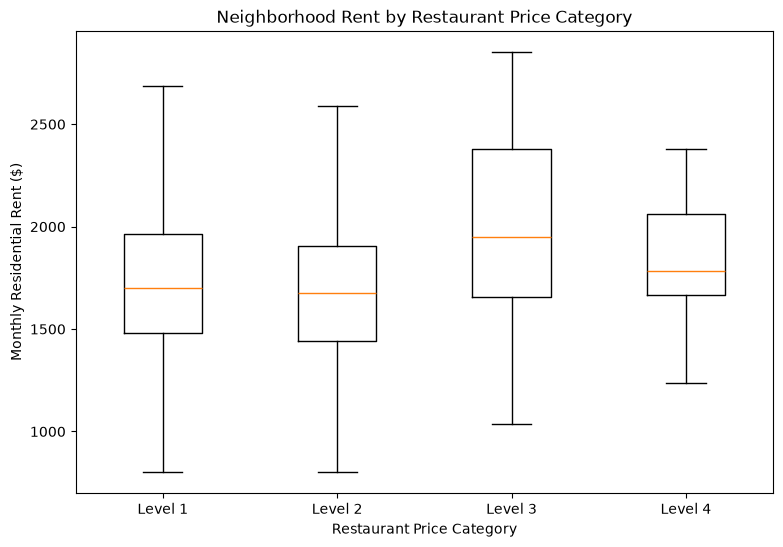

In [54]:
import matplotlib.pyplot as plt

data = [
    analysis.loc[analysis["price_level"] == i, "rent_2022"]
    for i in [1, 2, 3, 4]
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    data,
    tick_labels=["Level 1", "Level 2", "Level 3", "Level 4"],
    showfliers=False
)

ax.set_xlabel("Restaurant Price Category")
ax.set_ylabel("Monthly Residential Rent ($)")
ax.set_title("Neighborhood Rent by Restaurant Price Category")

plt.show()

**What does the result tell you?** (one or two sentences)

## B7. Submit

1. Run the cell below.
2. Answer the two reflection questions in `labs/lab2.md`.
3. Save this notebook (Cmd+S), then commit and push: **Source Control** → `Lab 2` → **Commit** → **Sync Changes**.
4. Paste your repo URL into the Lab 2 assignment on CourseWorks.

In [55]:
con.close()
print("Done. Save, commit, push, and submit your repo URL.")

Done. Save, commit, push, and submit your repo URL.
